# NEUR30006 final project: symbol lexicon, baseline vs rotational augmentation

**Edited version of `RANN_finish_project.ipynb`.** It now matches the report and the submitted data files instead of the earlier 100-node / 4-epoch / ±8° + shift recipe.

**What this notebook does**
1. Loads `symbols_training.csv` (500) and `symbols_testing.csv` (500) and checks them.
2. Rebuilds the augmented training sets from the training CSV only, using rotations: **3x** (0°, +10°, +20°) and **4x** (−10°, 0°, +10°, +20°). It then **verifies that the 4x set is identical to your submitted `symbols_training_augmented.csv`**. That file is never overwritten.
3. Trains the course-style ANN (784 → 200 → 10, sigmoid, no bias, one image at a time, learning rate 0.1, 10 epochs) for every condition, **shuffling the training order every epoch**, over **10 random seeds**.
4. Reports mean ± SD test accuracy on the untouched 500 test images, confusion matrices, per-class accuracy, and the test images that are persistently misclassified.
5. Adds a clearly separated **secondary robustness analysis**: the same trained models are scored on rotated *copies* of the test images. The headline result always uses the untouched test set.

**How to run:** put this notebook in the folder that holds the CSVs (or in a sub-folder of it), then choose **Run → Run All Cells**. Expect roughly 5–10 minutes. Everything it writes goes to a new `outputs/` folder.

**Rules this notebook enforces**
- The test set is never augmented and never used for training.
- The submitted CSV files are never overwritten (the notebook asserts this).
- Positive rotation angles are anticlockwise (SciPy's convention).

In [1]:
from pathlib import Path
import csv, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.ndimage import rotate

# ---------------- settings (keep in sync with the report) ----------------
HIDDEN_NODES   = 200
LEARNING_RATE  = 0.1
EPOCHS         = 10
N_SEEDS        = 10          # independent runs per condition
RUN_SYMMETRIC  = True        # exploratory extra condition (-20..+20 degrees)
ROBUSTNESS_ANGLES = [-30, -20, -10, 0, 10, 20, 30]
# --------------------------------------------------------------------------

# Find the project folder (works from the folder itself or a sub-folder of it).
candidates = [Path.cwd(), Path.cwd().parent, Path.home() / "Desktop" / "Artificial Neuro Final assignment"]
project = next((p for p in candidates
                if (p / "symbols_training.csv").exists() and (p / "symbols_testing.csv").exists()), None)
if project is None:
    raise FileNotFoundError("symbols_training.csv / symbols_testing.csv not found. "
                            "Put this notebook in the folder that contains them.")
OUT = project / "outputs"
OUT.mkdir(exist_ok=True)
print("Project folder:", project)
print("Outputs folder:", OUT)

train_raw = np.loadtxt(project / "symbols_training.csv", delimiter=",", dtype=np.float32)
test_raw  = np.loadtxt(project / "symbols_testing.csv",  delimiter=",", dtype=np.float32)
assert train_raw.shape == (500, 785) and test_raw.shape == (500, 785)
for name, a in [("training", train_raw), ("testing", test_raw)]:
    assert set(np.unique(a[:, 0]).astype(int)) == set(range(10))
    assert np.all((a[:, 1:] >= 0) & (a[:, 1:] <= 255))
    print(f"{name}: {a.shape}, per-class counts {np.bincount(a[:, 0].astype(int), minlength=10)}")
print("Distinct pixel values (grayscale levels) in training data:", len(np.unique(train_raw[:, 1:])))
print("Training file is sorted by class:", bool(np.all(np.diff(train_raw[:, 0]) >= 0)),
      "-> training order is shuffled every epoch below (an unshuffled run learns class blocks and scores far lower).")
test_labels = test_raw[:, 0].astype(int)

Project folder: <your project folder>
Outputs folder: <your project folder>/outputs
training: (500, 785), per-class counts [50 50 50 50 50 50 50 50 50 50]
testing: (500, 785), per-class counts [50 50 50 50 50 50 50 50 50 50]
Distinct pixel values (grayscale levels) in training data: 256
Training file is sorted by class: True -> training order is shuffled every epoch below (an unshuffled run learns class blocks and scores far lower).


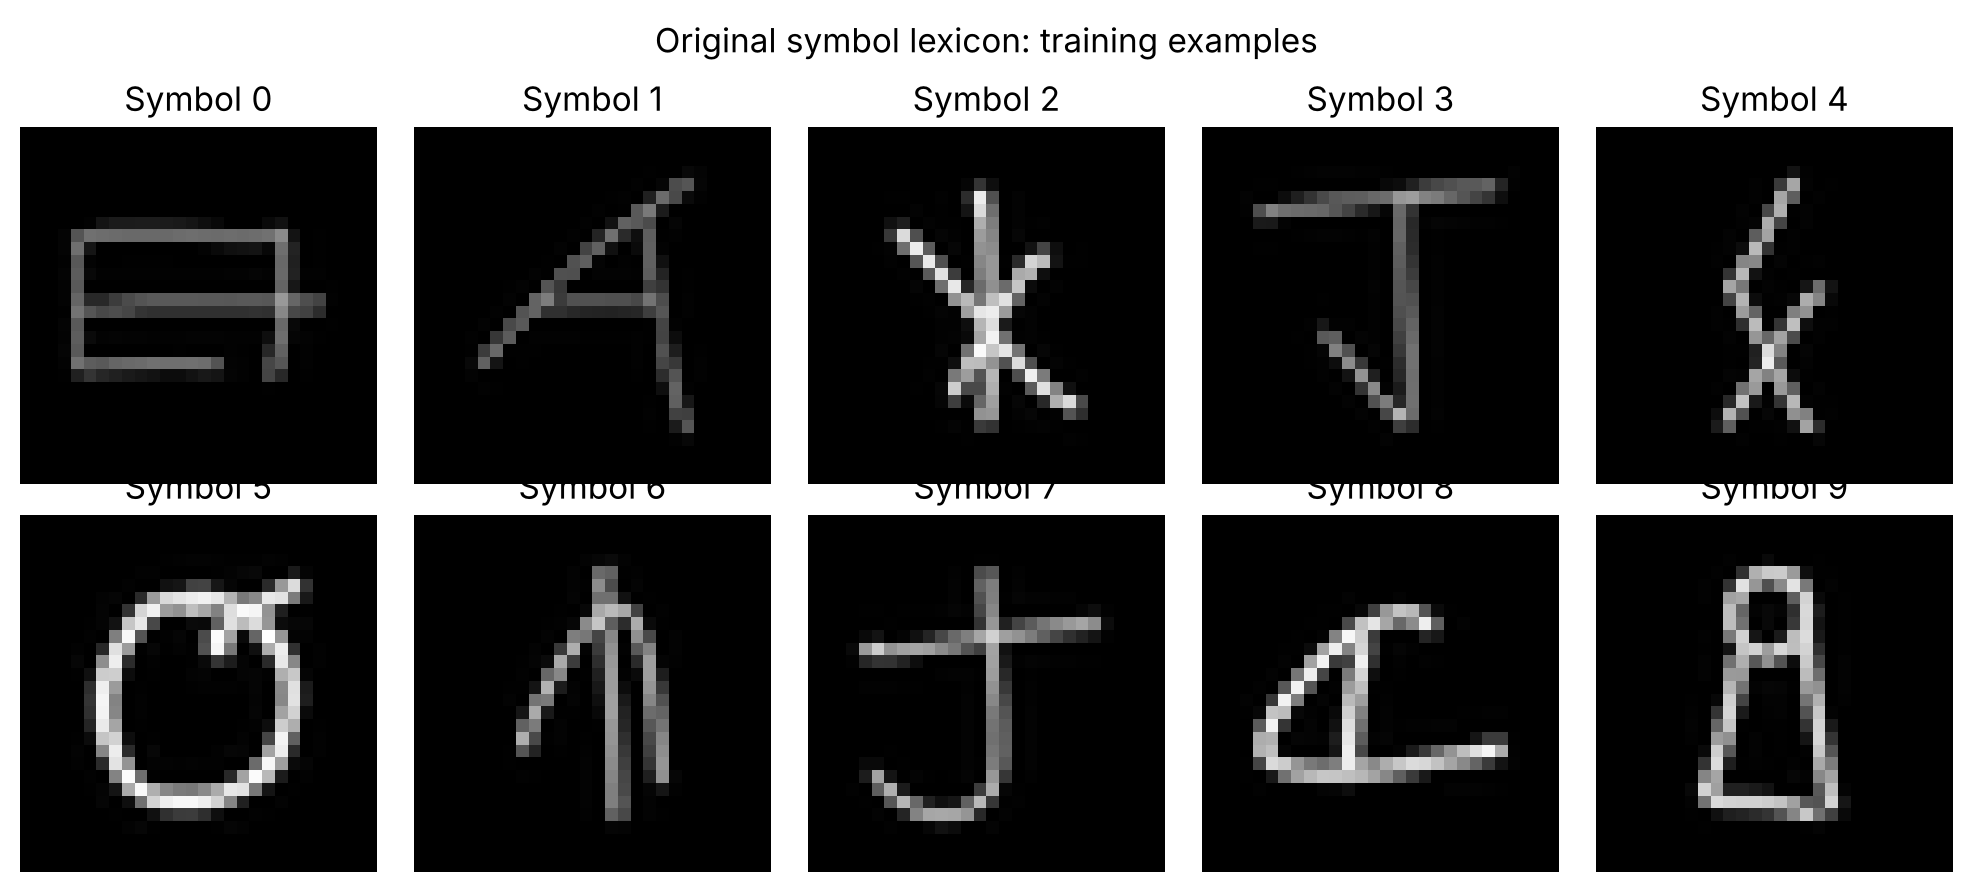

In [2]:
# Figure 1: one training example per class (light strokes on a dark background).
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for k in range(10):
    i = np.where(train_raw[:, 0] == k)[0][0]
    ax.flat[k].imshow(train_raw[i, 1:].reshape(28, 28), cmap="gray", vmin=0, vmax=255)
    ax.flat[k].set_title(f"Symbol {k}")
    ax.flat[k].axis("off")
fig.suptitle("Original symbol lexicon: training examples")
fig.tight_layout()
fig.savefig(OUT / "figure_1_symbol_lexicon.png", dpi=160, bbox_inches="tight")
plt.show()

## 1. The course ANN

Fully connected, 784 inputs, one hidden layer, 10 outputs, sigmoid activation, **no bias terms**, one image per weight update (no batching). The class is the course (Rashid) code; the only additions are a seed for reproducibility and a shuffled presentation order.

In [3]:
class neuralNetwork:
    def __init__(self, inputnodes, hiddennodes, outputnodes, learningrate):
        self.inodes, self.hnodes, self.onodes, self.lr = inputnodes, hiddennodes, outputnodes, learningrate
        self.wih = np.random.normal(0.0, pow(self.inodes, -0.5), (self.hnodes, self.inodes))
        self.who = np.random.normal(0.0, pow(self.hnodes, -0.5), (self.onodes, self.hnodes))
        self.activation_function = expit

    def train(self, inputs_list, targets_list):
        inputs  = np.array(inputs_list,  ndmin=2).T
        targets = np.array(targets_list, ndmin=2).T
        hidden_outputs = self.activation_function(np.dot(self.wih, inputs))
        final_outputs  = self.activation_function(np.dot(self.who, hidden_outputs))
        output_errors  = targets - final_outputs
        hidden_errors  = np.dot(self.who.T, output_errors)
        self.who += self.lr * np.dot(output_errors * final_outputs * (1.0 - final_outputs), hidden_outputs.T)
        self.wih += self.lr * np.dot(hidden_errors * hidden_outputs * (1.0 - hidden_outputs), inputs.T)

    def query(self, inputs_list):
        inputs = np.array(inputs_list, ndmin=2).T
        hidden_outputs = self.activation_function(np.dot(self.wih, inputs))
        return self.activation_function(np.dot(self.who, hidden_outputs))

def scale_pixels(raw):            # course-style MNIST scaling (no exact zeros)
    return raw / 255.0 * 0.99 + 0.01

def make_targets(label):
    t = np.zeros(10) + 0.01
    t[int(label)] = 0.99
    return t

def fit_network(rows, epochs, seed):
    # Same seed -> same starting weights and same presentation order.
    np.random.seed(seed)
    net = neuralNetwork(784, HIDDEN_NODES, 10, LEARNING_RATE)
    rng = np.random.default_rng(seed + 1000)
    X = scale_pixels(rows[:, 1:])
    T = np.array([make_targets(l) for l in rows[:, 0]])
    for _ in range(epochs):
        for i in rng.permutation(len(rows)):
            net.train(X[i], T[i])
    return net

def predict(net, rows):
    return np.array([int(np.argmax(net.query(scale_pixels(r[1:])))) for r in rows])

print(f"Network: 784 -> {HIDDEN_NODES} -> 10; sigmoid; lr {LEARNING_RATE}; {EPOCHS} epochs; no bias; one image per update; shuffled each epoch.")

Network: 784 -> 200 -> 10; sigmoid; lr 0.1; 10 epochs; no bias; one image per update; shuffled each epoch.


## 2. Augmentation (training images only)

`rotate_rows` uses `scipy.ndimage.rotate` with bilinear interpolation (`order=1`), `reshape=False` (the 28×28 frame is kept, so corners can be clipped) and a black background. Results are rounded to integers 0–255 to match the CSV format. The 0° copy is the original image.

In [4]:
def rotate_rows(rows, angle):
    out = rows.copy()
    if angle == 0:
        return out
    for i, r in enumerate(rows):
        im = r[1:].astype(np.float64).reshape(28, 28)   # float64 so rounding matches the submitted file
        rot = rotate(im, angle, reshape=False, order=1, mode="constant", cval=0.0)
        out[i, 1:] = np.clip(np.rint(rot), 0, 255).reshape(-1)
    return out

def build_augmented(rows, angles):
    return np.concatenate([rotate_rows(rows, a) for a in angles])

aug3 = build_augmented(train_raw, [0, 10, 20])            # 3x  = 1,500 images
aug4 = build_augmented(train_raw, [-10, 0, 10, 20])       # 4x  = 2,000 images
aug5 = build_augmented(train_raw, [-20, -10, 0, 10, 20])  # 5x  = 2,500 images (exploratory, symmetric)
print("3x:", aug3.shape, " 4x:", aug4.shape, " 5x symmetric:", aug5.shape)

# --- Verify the 4x set equals the SUBMITTED augmented CSV (order ignored) ---
submitted_path = project / "symbols_training_augmented.csv"
submitted = np.loadtxt(submitted_path, delimiter=",")
as_rows = lambda a: sorted(map(tuple, np.rint(a).astype(int).tolist()))
identical = as_rows(aug4) == as_rows(submitted)
print("Submitted symbols_training_augmented.csv shape:", submitted.shape)
print("Rebuilt 4x set identical to submitted file (ignoring row order):", identical)
assert identical, "The submitted augmented CSV does not match the -10/0/+10/+20 rotation recipe."

# Document the 3x set in the same CSV format. This is a NEW file in outputs/; submitted files are never touched.
with open(OUT / "symbols_training_augmented_3x.csv", "w", newline="") as f:
    w = csv.writer(f)
    for row in aug3:
        w.writerow(np.rint(row).astype(int))
assert OUT.resolve() != project.resolve()
print("Saved outputs/symbols_training_augmented_3x.csv (new file).")

3x: (1500, 785)  4x: (2000, 785)  5x symmetric: (2500, 785)


Submitted symbols_training_augmented.csv shape: (2000, 785)
Rebuilt 4x set identical to submitted file (ignoring row order): True
Saved outputs/symbols_training_augmented_3x.csv (new file).


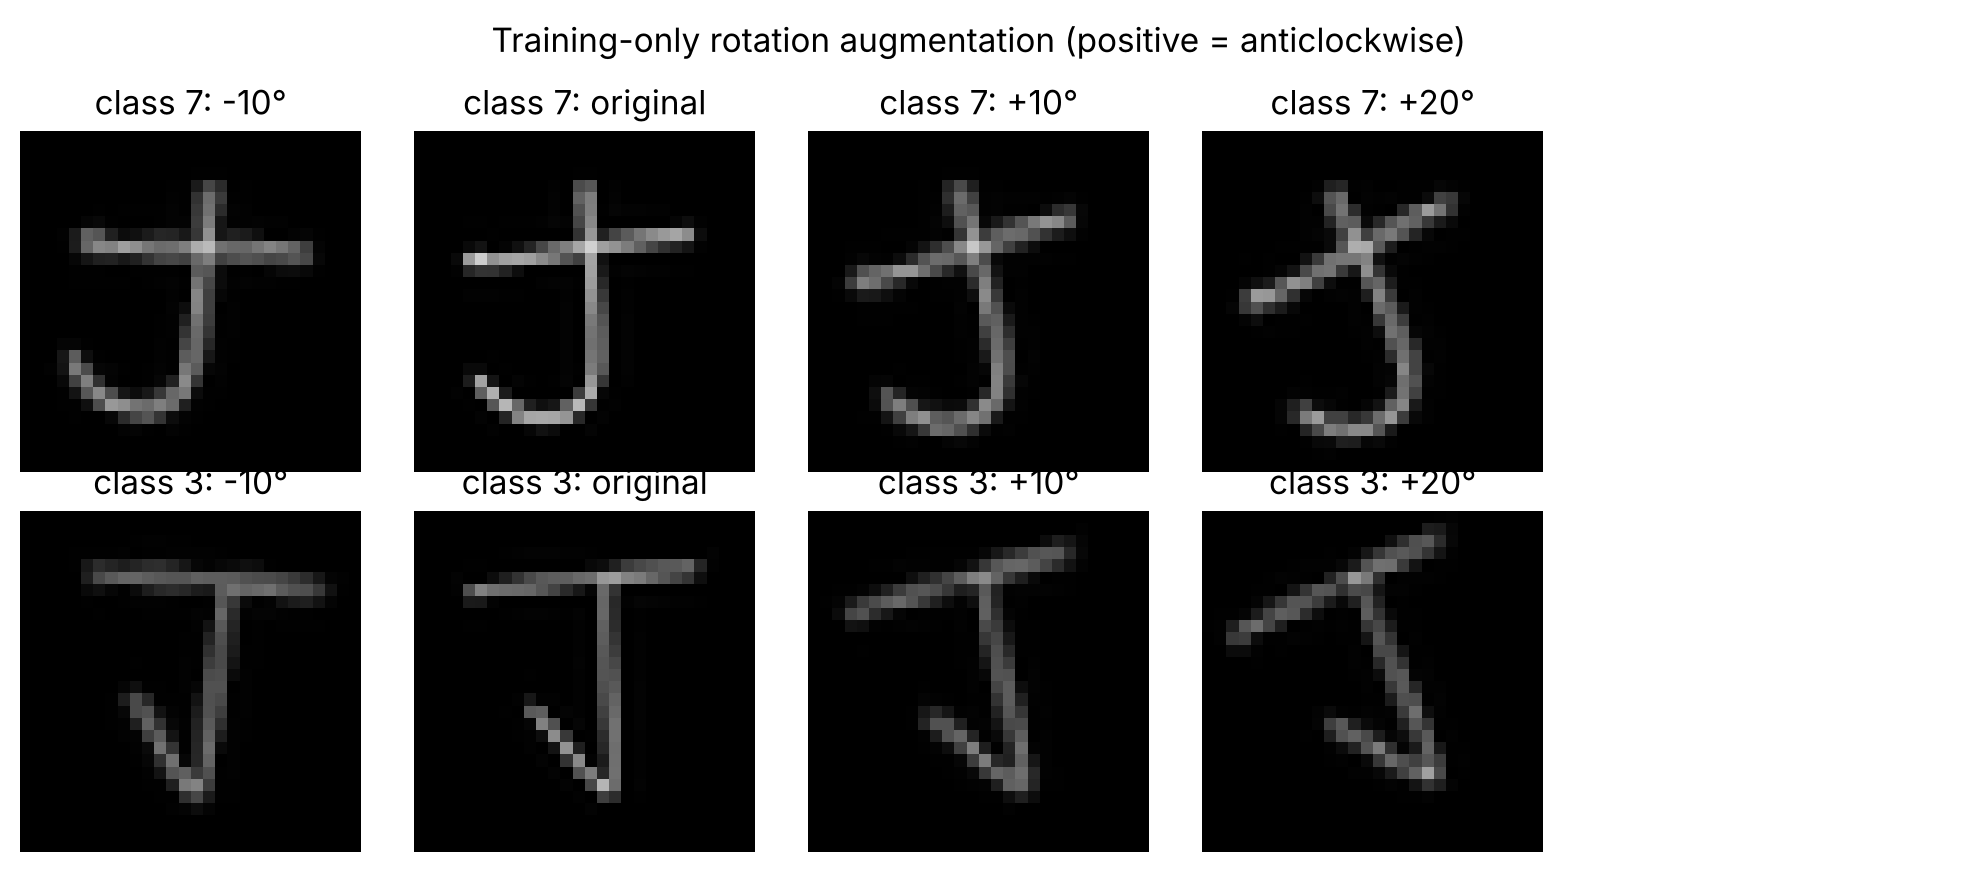

In [5]:
# Figure 2: augmentation example (class 7 and class 3, the two hook-shaped symbols).
fig, axs = plt.subplots(2, 5, figsize=(10, 4.4))
for r_i, cls in enumerate([7, 3]):
    ex = train_raw[np.where(train_raw[:, 0] == cls)[0][0]]
    for c_i, a in enumerate([-10, 0, 10, 20]):
        axs[r_i, c_i].imshow(rotate_rows(ex[None, :], a)[0, 1:].reshape(28, 28), cmap="gray", vmin=0, vmax=255)
        axs[r_i, c_i].set_title(f"class {cls}: {a:+d}°" if a else f"class {cls}: original")
        axs[r_i, c_i].axis("off")
    axs[r_i, 4].axis("off")
fig.suptitle("Training-only rotation augmentation (positive = anticlockwise)")
fig.tight_layout()
fig.savefig(OUT / "figure_2_augmentation.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Experiment: baseline vs augmented, same network, same settings

Every condition uses the same hidden nodes, learning rate and epochs (10) and the same seeds, so only the training set differs. The **control** trains the baseline for 40 epochs so it receives the same number of weight updates as the 4x set at 10 epochs (500 × 40 = 2,000 × 10); this separates "more training updates" from "more varied images".

The test set is the untouched 500 images. For the secondary robustness analysis, rotated copies of the test images are scored with the same trained models; they are never used for training.

In [6]:
CONDITIONS = [
    ("Baseline (500 images)",                         train_raw, EPOCHS),
    ("3x rotation (0, +10, +20)",                     aug3,      EPOCHS),
    ("4x rotation (-10, 0, +10, +20)",                aug4,      EPOCHS),
    ("Control: baseline, 40 epochs (= updates of 4x)", train_raw, EPOCHS * 4),
]
if RUN_SYMMETRIC:
    CONDITIONS.append(("Exploratory: 5x symmetric (-20..+20)", aug5, EPOCHS))

# Rotated COPIES of the test set (analysis only).
rotated_tests = {a: rotate_rows(test_raw, a) for a in ROBUSTNESS_ANGLES}

results = {}
t_start = time.time()
for name, rows, epochs in CONDITIONS:
    per_seed = []
    t0 = time.time()
    for seed in range(N_SEEDS):
        net = fit_network(rows, epochs, seed)
        test_pred  = predict(net, test_raw)
        train_pred = predict(net, train_raw)
        robust = {a: int((predict(net, rotated_tests[a]) == test_labels).sum()) for a in ROBUSTNESS_ANGLES}
        robust_pred = {a: predict(net, rotated_tests[a]) for a in (-20, 20)}
        per_seed.append(dict(seed=seed, test_pred=test_pred,
                             test_correct=int((test_pred == test_labels).sum()),
                             train_correct=int((train_pred == train_raw[:, 0].astype(int)).sum()),
                             robust=robust, robust_pred=robust_pred))
    results[name] = per_seed
    c = [r["test_correct"] for r in per_seed]
    print(f"{name:52s} {len(rows):5d} imgs, {epochs:2d} ep | correct/500 per seed {c} | {time.time()-t0:.0f}s")
print(f"Total time: {time.time()-t_start:.0f}s")

Baseline (500 images)                                  500 imgs, 10 ep | correct/500 per seed [498, 498, 498, 498, 497, 497, 498, 498, 498, 497] | 15s


3x rotation (0, +10, +20)                             1500 imgs, 10 ep | correct/500 per seed [496, 496, 496, 497, 496, 497, 496, 497, 496, 497] | 52s


4x rotation (-10, 0, +10, +20)                        2000 imgs, 10 ep | correct/500 per seed [498, 498, 498, 497, 497, 498, 498, 497, 498, 498] | 65s


Control: baseline, 40 epochs (= updates of 4x)         500 imgs, 40 ep | correct/500 per seed [499, 499, 499, 499, 499, 499, 499, 499, 499, 499] | 60s


Exploratory: 5x symmetric (-20..+20)                  2500 imgs, 10 ep | correct/500 per seed [498, 498, 496, 498, 497, 497, 498, 498, 498, 498] | 83s
Total time: 275s


## 4. Results for the report (untouched test set)

In [7]:
def summarise(name):
    c = np.array([r["test_correct"] for r in results[name]])
    tr = np.array([r["train_correct"] for r in results[name]])
    return c, tr

base_name = CONDITIONS[0][0]
base_c, _ = summarise(base_name)
rows_out = []
print(f"{'Condition':52s} {'train n':>7s} {'epochs':>6s} {'mean correct':>12s} {'SD':>5s} {'min-max':>8s} {'mean acc %':>10s} {'diff vs baseline (images)':>26s}")
for name, rows, epochs in CONDITIONS:
    c, tr = summarise(name)
    diff = c - base_c                      # paired by seed
    print(f"{name:52s} {len(rows):7d} {epochs:6d} {c.mean():12.1f} {c.std(ddof=1):5.2f} {c.min():3d}-{c.max():<4d} {c.mean()/5:10.2f} {diff.mean():+14.1f} (SD {diff.std(ddof=1):.1f})")
    rows_out.append([name, len(rows), len(test_raw), HIDDEN_NODES, LEARNING_RATE, epochs, N_SEEDS,
                     round(c.mean(), 2), round(c.std(ddof=1), 3), int(c.min()), int(c.max()),
                     round(c.mean()/5, 3), round(tr.mean()/5, 3), round(diff.mean(), 2)])

with open(OUT / "experiment_results.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["Condition", "Training images", "Test images", "Hidden nodes", "Learning rate", "Epochs", "Seeds",
                "Mean correct /500", "SD correct", "Min correct", "Max correct", "Mean test accuracy (%)",
                "Mean accuracy on original train images (%)", "Mean paired difference vs baseline (images)"])
    w.writerows(rows_out)
with open(OUT / "seed_results.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["Condition", "Seed", "Test correct /500", "Test accuracy (%)", "Original-train correct /500"])
    for name, _, _ in CONDITIONS:
        for r in results[name]:
            w.writerow([name, r["seed"], r["test_correct"], r["test_correct"]/5, r["train_correct"]])
print("\nSaved outputs/experiment_results.csv and outputs/seed_results.csv")
print("Note: 1 test image = 0.2 percentage points. Compare differences with the seed-to-seed SD before calling them real.")

Condition                                            train n epochs mean correct    SD  min-max mean acc %  diff vs baseline (images)
Baseline (500 images)                                    500     10        497.7  0.48 497-498       99.54           +0.0 (SD 0.0)
3x rotation (0, +10, +20)                               1500     10        496.4  0.52 496-497       99.28           -1.3 (SD 0.8)
4x rotation (-10, 0, +10, +20)                          2000     10        497.7  0.48 497-498       99.54           +0.0 (SD 0.7)
Control: baseline, 40 epochs (= updates of 4x)           500     40        499.0  0.00 499-499       99.80           +1.3 (SD 0.5)
Exploratory: 5x symmetric (-20..+20)                    2500     10        497.6  0.70 496-498       99.52           -0.1 (SD 0.7)

Saved outputs/experiment_results.csv and outputs/seed_results.csv
Note: 1 test image = 0.2 percentage points. Compare differences with the seed-to-seed SD before calling them real.


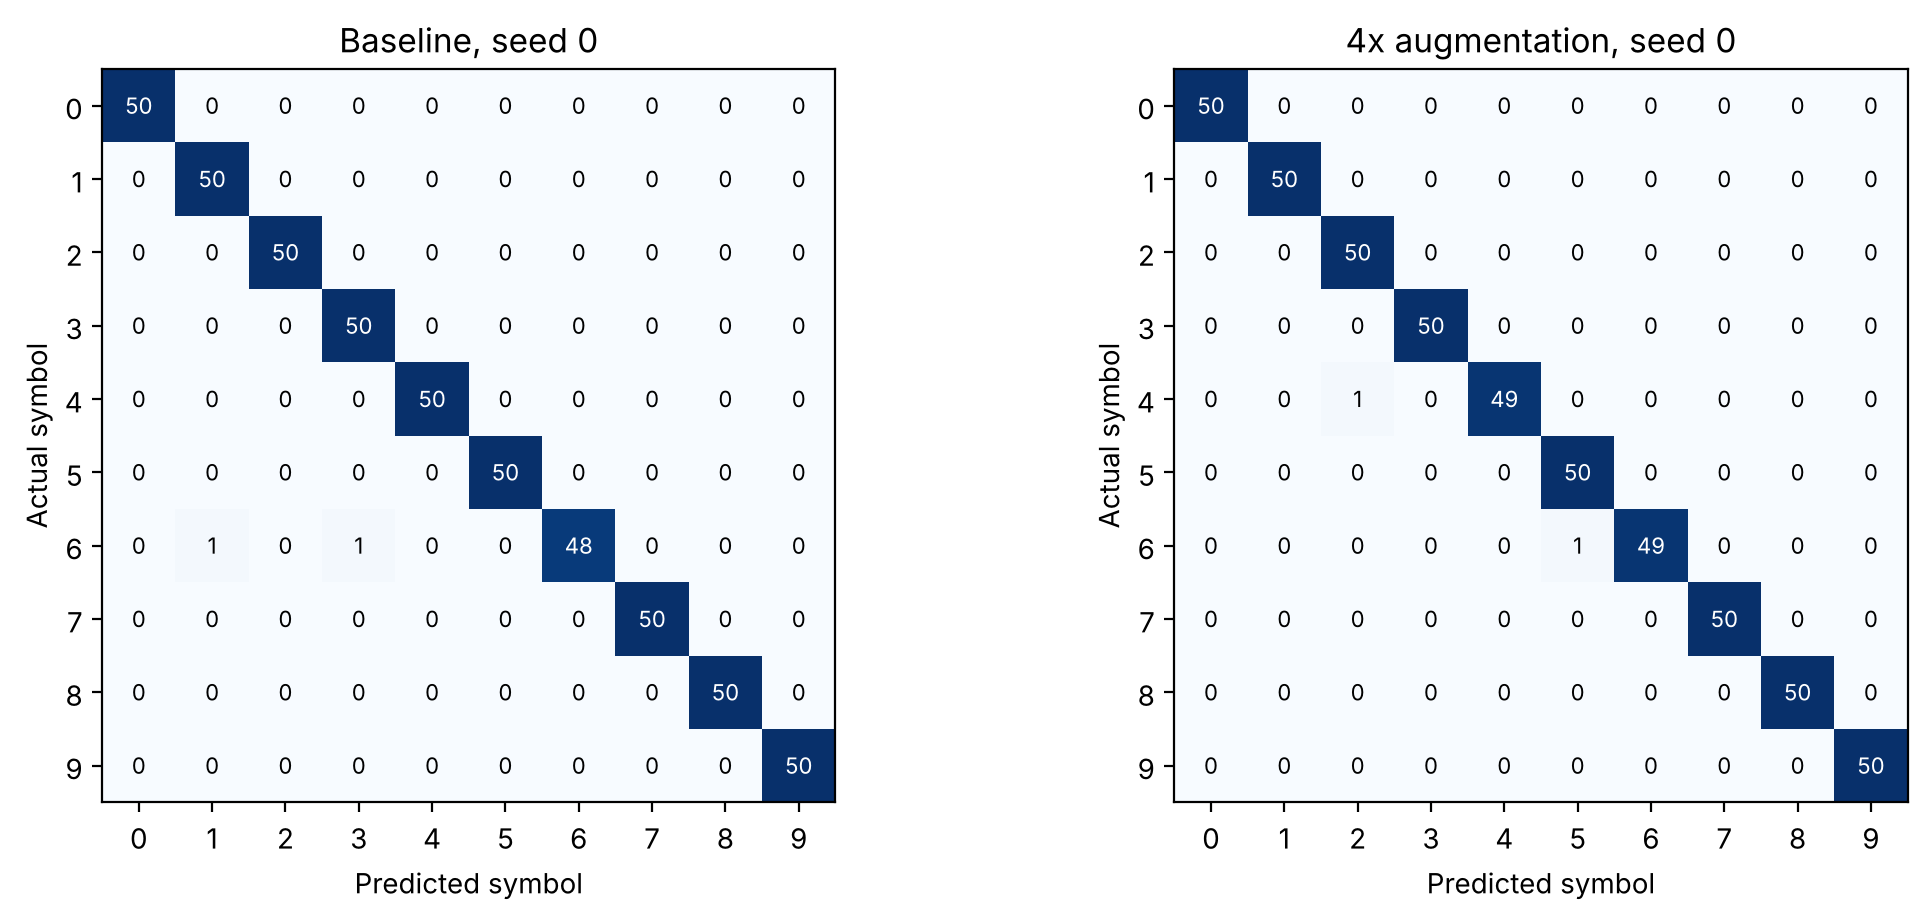

Baseline (500 images): most frequent errors over 10 seeds (true->predicted, count): [('6->3', 10), ('6->1', 6), ('1->6', 6), ('8->5', 1)]
3x rotation (0, +10, +20): most frequent errors over 10 seeds (true->predicted, count): [('4->2', 10), ('6->1', 9), ('8->2', 7), ('6->7', 5), ('6->8', 4), ('6->5', 1)]
4x rotation (-10, 0, +10, +20): most frequent errors over 10 seeds (true->predicted, count): [('4->2', 10), ('6->5', 9), ('8->2', 3), ('6->8', 1)]
Control: baseline, 40 epochs (= updates of 4x): most frequent errors over 10 seeds (true->predicted, count): [('6->3', 10)]
Exploratory: 5x symmetric (-20..+20): most frequent errors over 10 seeds (true->predicted, count): [('6->5', 10), ('4->2', 10), ('8->2', 2), ('5->7', 2)]


In [8]:
# Confusion matrices (seed 0) and pooled over all seeds, baseline vs 4x.
def confusion(true, pred):
    cm = np.zeros((10, 10), dtype=int)
    for t, p in zip(true, pred):
        cm[t, p] += 1
    return cm

four_name = CONDITIONS[2][0]
cm_base0 = confusion(test_labels, results[base_name][0]["test_pred"])
cm_four0 = confusion(test_labels, results[four_name][0]["test_pred"])

fig, axs = plt.subplots(1, 2, figsize=(11, 4.7))
for ax, cm, title in [(axs[0], cm_base0, "Baseline, seed 0"), (axs[1], cm_four0, "4x augmentation, seed 0")]:
    ax.imshow(cm, cmap="Blues", vmin=0)
    ax.set_title(title); ax.set_xlabel("Predicted symbol"); ax.set_ylabel("Actual symbol")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 25 else "black")
fig.tight_layout()
fig.savefig(OUT / "figure_3_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

def pooled_confusions(name, k=6):
    cm = np.zeros((10, 10), dtype=int)
    for r in results[name]:
        cm += confusion(test_labels, r["test_pred"])
    off = sorted([(cm[i, j], i, j) for i in range(10) for j in range(10) if i != j], reverse=True)
    return [(f"{i}->{j}", int(n)) for n, i, j in off[:k] if n > 0]

for name, _, _ in CONDITIONS:
    print(f"{name}: most frequent errors over {N_SEEDS} seeds (true->predicted, count):", pooled_confusions(name))

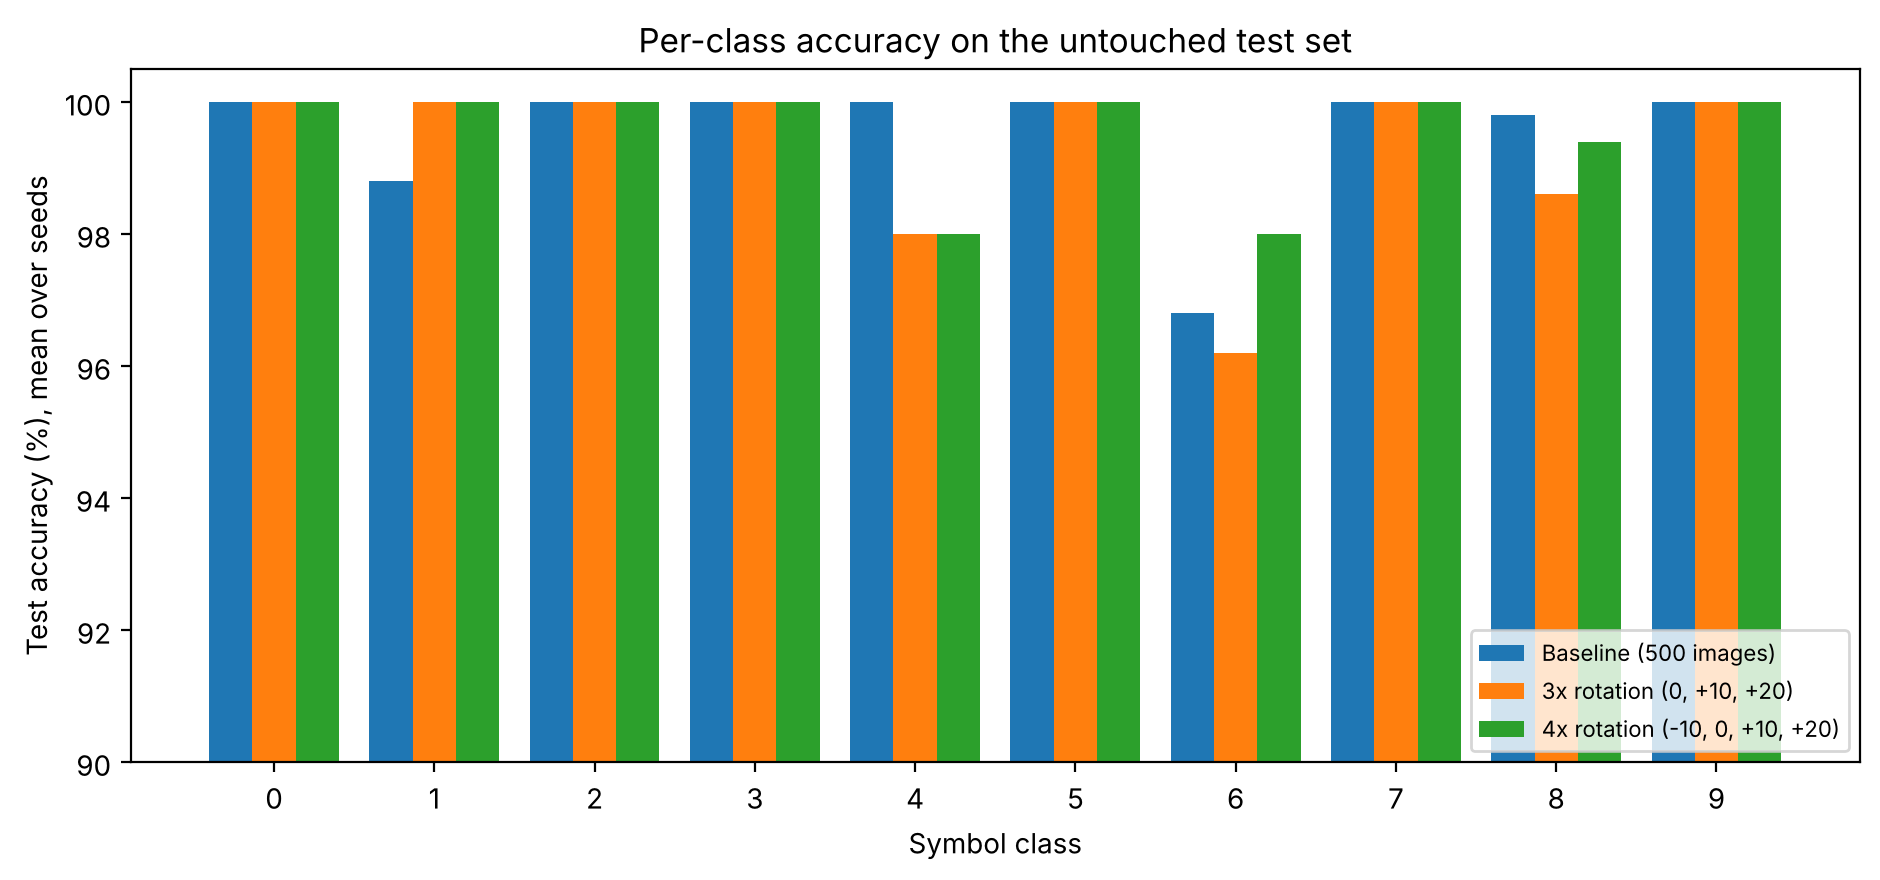

(y-axis starts at 90% so small differences are visible; every bar is above 90%.)
Saved outputs/class_results.csv


In [9]:
# Per-class test accuracy (mean over seeds).
fig, ax = plt.subplots(figsize=(9.5, 4.5))
show = [CONDITIONS[0][0], CONDITIONS[1][0], CONDITIONS[2][0]]
w = 0.27
class_rows = []
for k, name in enumerate(show):
    accs = np.array([[100 * np.mean(r["test_pred"][test_labels == c] == c) for c in range(10)] for r in results[name]])
    ax.bar(np.arange(10) + (k - 1) * w, accs.mean(axis=0), width=w, label=name)
    class_rows.append((name, accs.mean(axis=0)))
ax.set(xlabel="Symbol class", ylabel="Test accuracy (%), mean over seeds", title="Per-class accuracy on the untouched test set",
       xticks=range(10), ylim=(90, 100.5))
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "figure_4_class_accuracy.png", dpi=160, bbox_inches="tight")
plt.show()
print("(y-axis starts at 90% so small differences are visible; every bar is above 90%.)")
with open(OUT / "class_results.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["Class"] + [f"{n} mean test accuracy (%)" for n, _ in class_rows])
    for c in range(10):
        wr.writerow([c] + [round(a[c], 2) for _, a in class_rows])
print("Saved outputs/class_results.csv")

## 5. Which test images are misclassified? (for the Discussion)

Images that the **4x model** gets wrong in several seeds are listed here, with the label it most often predicts. Look at them: that is the evidence for *why* a class is confused, which the confusion matrix alone cannot give.

Baseline (500 images): test images misclassified most often (row index, seeds wrong of 10, most common wrong label):
    [(345, '10/10', 'true 6->pred 3'), (339, '6/10', 'true 6->pred 1'), (88, '5/10', 'true 1->pred 6'), (421, '1/10', 'true 8->pred 5'), (63, '1/10', 'true 1->pred 6')]
4x rotation (-10, 0, +10, +20): test images misclassified most often (row index, seeds wrong of 10, most common wrong label):
    [(345, '10/10', 'true 6->pred 5'), (237, '10/10', 'true 4->pred 2'), (416, '3/10', 'true 8->pred 2')]


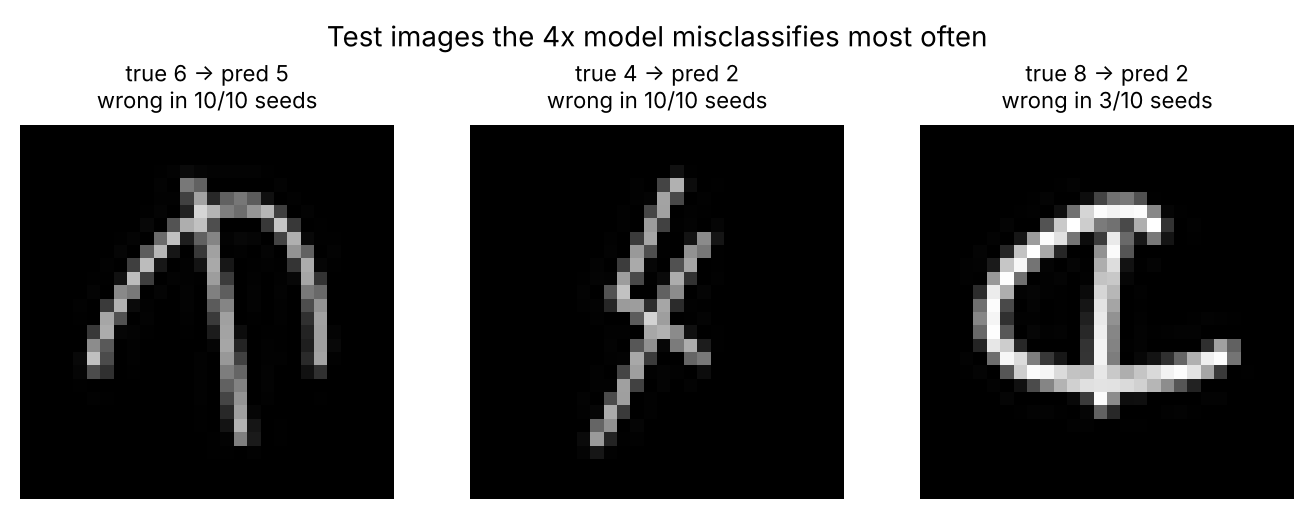

In [10]:
def persistent_errors(name, top=10):
    wrong = np.zeros(len(test_labels), dtype=int)
    votes = np.zeros((len(test_labels), 10), dtype=int)
    for r in results[name]:
        p = r["test_pred"]
        bad = p != test_labels
        wrong += bad
        votes[np.where(bad)[0], p[bad]] += 1      # count only WRONG predictions
    order = np.argsort(-wrong)
    return [(int(i), int(wrong[i]), int(votes[i].argmax())) for i in order[:top] if wrong[i] > 0]

for name in (base_name, four_name):
    errs = persistent_errors(name)
    print(f"{name}: test images misclassified most often (row index, seeds wrong of {N_SEEDS}, most common wrong label):")
    print("   ", [(i, f"{w}/{N_SEEDS}", f"true {test_labels[i]}->pred {v}") for i, w, v in errs])

errs = persistent_errors(four_name, top=10)
if errs:
    cols = min(5, len(errs)); rws = int(np.ceil(len(errs) / cols))
    fig, axs = plt.subplots(rws, cols, figsize=(2.3 * cols, 2.6 * rws), squeeze=False)
    for ax in axs.flat: ax.axis("off")
    for ax, (i, wcount, v) in zip(axs.flat, errs):
        ax.imshow(test_raw[i, 1:].reshape(28, 28), cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"true {test_labels[i]} -> pred {v}\nwrong in {wcount}/{N_SEEDS} seeds", fontsize=8)
    fig.suptitle("Test images the 4x model misclassifies most often", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / "figure_5_misclassified_examples.png", dpi=160, bbox_inches="tight")
    plt.show()

## 6. Secondary analysis: robustness to rotation (analysis only)

The headline result above uses the untouched test set. Here, the **same trained models** are scored on rotated copies of the test images. This tests what augmentation is meant to buy (tolerance to rotation) when the original test set is too easy to show it. The training range for 4x is −10° to +20°, so any asymmetry in the curve is expected to follow that range.

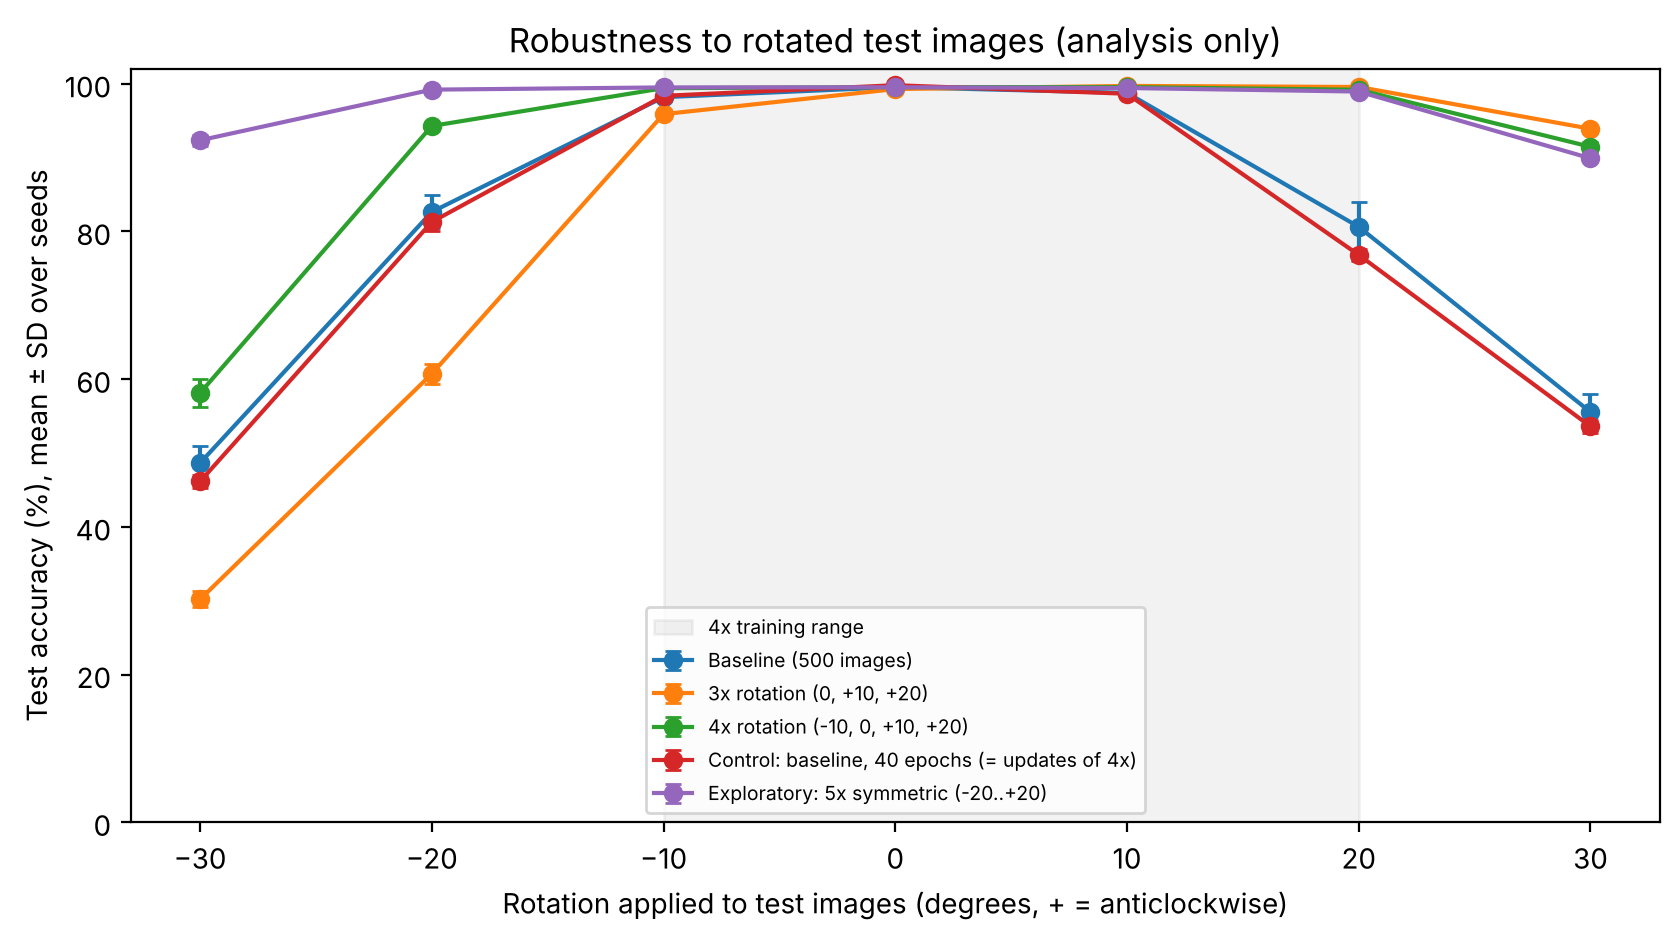

Condition                                                -30     -20     -10       0      10      20      30
Baseline (500 images)                                   48.6    82.6    98.2    99.5    98.8    80.6    55.5
3x rotation (0, +10, +20)                               30.2    60.7    95.9    99.3    99.7    99.6    93.9
4x rotation (-10, 0, +10, +20)                          58.1    94.3    99.4    99.5    99.5    99.2    91.5
Control: baseline, 40 epochs (= updates of 4x)          46.1    81.3    98.4    99.8    98.6    76.8    53.6
Exploratory: 5x symmetric (-20..+20)                    92.3    99.2    99.5    99.5    99.4    98.9    89.9

Baseline on test rotated -20 deg: per-class accuracy % [100, 98, 68, 100, 65, 93, 31, 97, 100, 73]
   most frequent errors (true->pred, count over seeds): [('6->1', 300), ('4->1', 170), ('2->4', 116), ('9->6', 105)]

Baseline on test rotated +20 deg: per-class accuracy % [94, 58, 95, 100, 37, 93, 92, 50, 100, 87]
   most frequent errors (true-

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
rob_rows = []
for name, _, _ in CONDITIONS:
    M = np.array([[r["robust"][a] / 5 for a in ROBUSTNESS_ANGLES] for r in results[name]])   # seeds x angles, in %
    ax.errorbar(ROBUSTNESS_ANGLES, M.mean(axis=0), yerr=M.std(axis=0, ddof=1), marker="o", capsize=3, label=name)
    for a, m, s in zip(ROBUSTNESS_ANGLES, M.mean(axis=0), M.std(axis=0, ddof=1)):
        rob_rows.append([name, a, round(m, 2), round(s, 2)])
ax.axvspan(-10, 20, color="grey", alpha=0.10, label="4x training range")
ax.set(xlabel="Rotation applied to test images (degrees, + = anticlockwise)", ylabel="Test accuracy (%), mean ± SD over seeds",
       title="Robustness to rotated test images (analysis only)", xticks=ROBUSTNESS_ANGLES, ylim=(0, 102))
ax.legend(fontsize=7, loc="lower center")
fig.tight_layout()
fig.savefig(OUT / "figure_6_rotation_robustness.png", dpi=160, bbox_inches="tight")
plt.show()

with open(OUT / "robustness_results.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["Condition", "Test rotation (deg)", "Mean accuracy (%)", "SD (%)"]); w.writerows(rob_rows)

print(f"{'Condition':52s}" + "".join(f"{a:>8d}" for a in ROBUSTNESS_ANGLES))
for name, _, _ in CONDITIONS:
    M = np.array([[r["robust"][a] / 5 for a in ROBUSTNESS_ANGLES] for r in results[name]])
    print(f"{name:52s}" + "".join(f"{m:8.1f}" for m in M.mean(axis=0)))

# Which classes fail when the baseline sees rotated images? (pooled over seeds)
for a in (-20, 20):
    P = np.concatenate([r["robust_pred"][a] for r in results[base_name]])
    Y = np.tile(test_labels, N_SEEDS)
    per_class = [round(100 * np.mean(P[Y == c] == c)) for c in range(10)]
    cm = confusion(Y, P)
    off = sorted([(cm[i, j], i, j) for i in range(10) for j in range(10) if i != j], reverse=True)[:4]
    print(f"\nBaseline on test rotated {a:+d} deg: per-class accuracy % {per_class}")
    print("   most frequent errors (true->pred, count over seeds):", [(f'{i}->{j}', int(n)) for n, i, j in off])
print("\nSaved outputs/robustness_results.csv")

## 7. Numbers for the report

In [12]:
print("================= RESULTS FOR REPORT (copy exactly) =================")
print(f"Dataset: 1,000 original drawings (100 per class, 10 classes); training {len(train_raw)}, testing {len(test_raw)}, split before augmentation (stratified, 50 per class).")
print(f"ANN: 784 inputs, {HIDDEN_NODES} hidden nodes, 10 outputs, sigmoid, lr {LEARNING_RATE}, {EPOCHS} epochs, no bias, one image per update, shuffled each epoch.")
print(f"Seeds: {N_SEEDS} per condition (seeds 0..{N_SEEDS-1}); results are mean +/- SD.")
print(f"Augmentation: rotation only; 3x = 0,+10,+20 (1,500 images); 4x = -10,0,+10,+20 (2,000 images, identical to the submitted CSV: {identical}).\n")
for name, rows, epochs in CONDITIONS:
    c, tr = summarise(name)
    print(f"{name}\n   test correct {c.mean():.1f} +/- {c.std(ddof=1):.2f} of 500  ({c.mean()/5:.2f}% +/- {c.std(ddof=1)/5:.2f});  range {c.min()}-{c.max()};  original-train accuracy {tr.mean()/5:.2f}%")
print("\nInterpretation guide (the notebook does not decide for you):")
print(" - 1 test image = 0.2 percentage points. If condition means differ by less than the seed-to-seed SD, say there is no measurable difference.")
print(" - Report the baseline exactly as produced here, even if augmentation does not help.")
print(" - The rotation-robustness curve is a secondary analysis on rotated copies of the test images, not part of the headline test accuracy.")
print("\nFiles written to", OUT)
for p in sorted(OUT.iterdir()): print("  ", p.name)

================= RESULTS FOR REPORT (copy exactly) =================
Dataset: 1,000 original drawings (100 per class, 10 classes); training 500, testing 500, split before augmentation (stratified, 50 per class).
ANN: 784 inputs, 200 hidden nodes, 10 outputs, sigmoid, lr 0.1, 10 epochs, no bias, one image per update, shuffled each epoch.
Seeds: 10 per condition (seeds 0..9); results are mean +/- SD.
Augmentation: rotation only; 3x = 0,+10,+20 (1,500 images); 4x = -10,0,+10,+20 (2,000 images, identical to the submitted CSV: True).

Baseline (500 images)
   test correct 497.7 +/- 0.48 of 500  (99.54% +/- 0.10);  range 497-498;  original-train accuracy 100.00%
3x rotation (0, +10, +20)
   test correct 496.4 +/- 0.52 of 500  (99.28% +/- 0.10);  range 496-497;  original-train accuracy 100.00%
4x rotation (-10, 0, +10, +20)
   test correct 497.7 +/- 0.48 of 500  (99.54% +/- 0.10);  range 497-498;  original-train accuracy 100.00%
Control: baseline, 40 epochs (= updates of 4x)
   test correct 

## 8. Submission checklist (from the course guide)

| Item | Where |
|---|---|
| Training dataset | `symbols_training.csv` (500) and `symbols_training_augmented.csv` (2,000; verified in this notebook) |
| Test dataset | `symbols_testing.csv` (500) |
| ANN source code | this notebook |
| Augmentation code | the `rotate_rows` / `build_augmented` cells above (the course expander notebook produced the same 4x file) |
| Project report | your `.docx`, 1,500 words, with the visual abstract |
| Results to quote | `outputs/experiment_results.csv`, `seed_results.csv`, `class_results.csv`, `robustness_results.csv`, figures 1–6 |

**Before you submit:** run all cells from a fresh kernel on your own machine and make sure every number in the report matches the printed output. Subject line must be exactly `final_project NEUR30006`.